# Precession

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch10/ch10-01.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** run the setup cell below first. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

In [ ]:
# --- Setup: run this cell first.  It does nothing outside Google Colab. ---
import sys, os, importlib.util, urllib.request
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # interactive matplotlib (%matplotlib widget) needs ipympl and Colab's custom widget manager
    if importlib.util.find_spec("ipympl") is None:
        get_ipython().run_line_magic("pip", "install -q ipympl")
        print("ipympl installed. Colab will restart the runtime once; when it has, run this cell again.")
        get_ipython().kernel.do_shutdown(restart=True)
    from google.colab import output
    output.enable_custom_widget_manager()

## Import libraries

## Define parameters

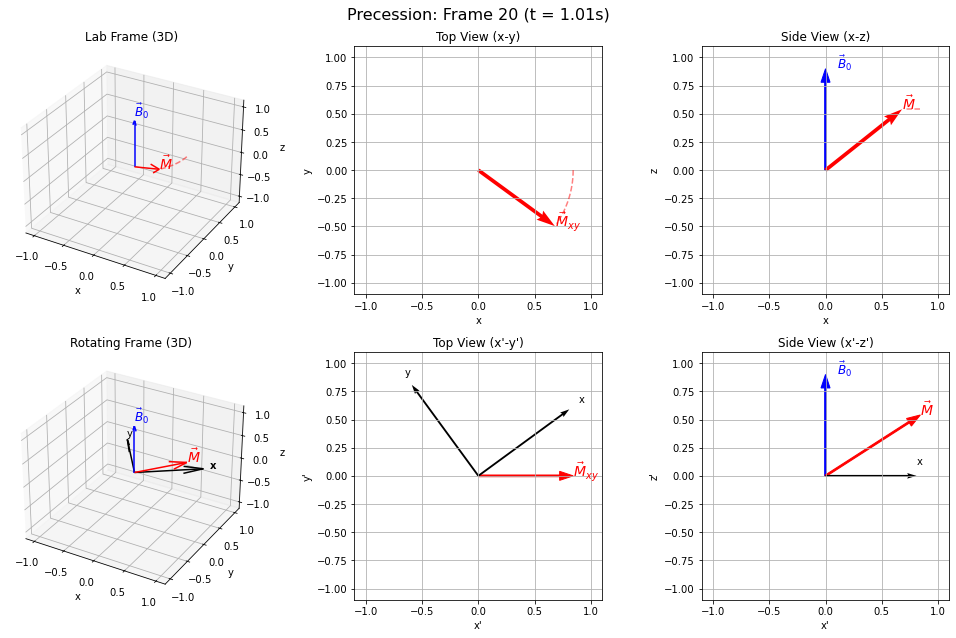

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# --- 1. Parameters & Physics ---
duration = 10.0
M0 = 1.0
alpha = 1.0          # Tilt angle (radians)
f0 = 0.1             # Frequency (Hz)
phi = 0
fps = 20             
n_frames = int(duration * fps)
times = np.linspace(0, duration, n_frames)

# Physics Calculations
omega = 2 * np.pi * f0
Mx_lab = M0 * np.sin(alpha) * np.cos(-omega * times + phi)
My_lab = M0 * np.sin(alpha) * np.sin(-omega * times + phi)
Mz_lab = M0 * np.cos(alpha) * np.ones_like(times)

Mx_rot = M0 * np.sin(alpha) * np.cos(phi)
My_rot = M0 * np.sin(alpha) * np.sin(phi)
Mz_rot = M0 * np.cos(alpha)

# --- 2. Plot Setup ---
fig1 = plt.figure(figsize=(14, 9))
target_frame = 20
fig1.suptitle(f"Precession: Frame {target_frame} (t = {times[target_frame]:.2f}s)", fontsize=16)

# Layout
ax_lab_3d   = fig1.add_subplot(2, 3, 1, projection='3d')
ax_lab_top  = fig1.add_subplot(2, 3, 2)
ax_lab_side = fig1.add_subplot(2, 3, 3)
ax_rot_3d   = fig1.add_subplot(2, 3, 4, projection='3d')
ax_rot_top  = fig1.add_subplot(2, 3, 5)
ax_rot_side = fig1.add_subplot(2, 3, 6)

# Setup Helpers
def setup_3d_ax(ax, title):
    ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1); ax.set_zlim(-1.1, 1.1)
    ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')
    ax.set_title(title)
    ax.quiver(0, 0, 0, 0, 0, 1, color='blue', length=1.0, arrow_length_ratio=0.1)
    ax.text(0, 0, 1.1, r'$\vec{B}_0$', color='blue', fontsize=12)

def setup_2d_ax(ax, title, xlabel, ylabel):
    ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(True)
    ax.set_aspect('equal', 'box')
    if 'z' in ylabel: 
        ax.arrow(0, 0, 0, 0.9, width=0.015, head_width=0.08, color='blue', length_includes_head=True)
        ax.text(0.1, 0.9, r'$\vec{B}_0$', color='blue', fontsize=12)

setup_3d_ax(ax_lab_3d, "Lab Frame (3D)")
setup_2d_ax(ax_lab_top, "Top View (x-y)", "x", "y")
setup_2d_ax(ax_lab_side, "Side View (x-z)", "x", "z")

setup_3d_ax(ax_rot_3d, "Rotating Frame (3D)")
setup_2d_ax(ax_rot_top, "Top View (x'-y')", "x'", "y'")
setup_2d_ax(ax_rot_side, "Side View (x'-z')", "x'", "z'")

# --- 3. Initialize Objects ---
# Lab Frame
line_lab_3d, = ax_lab_3d.plot([], [], [], 'r--', alpha=0.5) 
lbl_lab_3d = ax_lab_3d.text(0,0,0, r'$\vec{M}$', color='red', fontsize=14)
quiver_lab_3d = None 

line_lab_top, = ax_lab_top.plot([], [], 'r--', alpha=0.5)
quiver_lab_top = ax_lab_top.quiver([0], [0], [1], [0], color='r', angles='xy', scale_units='xy', scale=1, width=0.015)
lbl_lab_top = ax_lab_top.text(0,0, r'$\vec{M}_{xy}$', color='red', fontsize=14)

line_lab_side, = ax_lab_side.plot([], [], 'r--', alpha=0.5)
quiver_lab_side = ax_lab_side.quiver([0], [0], [1], [0], color='r', angles='xy', scale_units='xy', scale=1, width=0.015)
lbl_lab_side = ax_lab_side.text(0,0, r'$\vec{M}$', color='red', fontsize=14)

# Rotating Frame (Static Arrows)
ax_rot_3d.quiver(0, 0, 0, Mx_rot, My_rot, Mz_rot, color='red', length=1.0)
ax_rot_3d.text(Mx_rot, My_rot, Mz_rot, r'$\vec{M}$', color='red', fontsize=14)

ax_rot_top.arrow(0, 0, Mx_rot, My_rot, width=0.015, head_width=0.08, color='red', length_includes_head=True)
ax_rot_top.text(Mx_rot, My_rot, r'$\vec{M}_{xy}$', color='red', fontsize=14)

ax_rot_side.arrow(0, 0, Mx_rot, Mz_rot, width=0.015, head_width=0.08, color='red', length_includes_head=True)
ax_rot_side.text(Mx_rot, Mz_rot, r'$\vec{M}$', color='red', fontsize=14)

# Rotating Frame (Moving Axes)
quiver_rot_axes = None 
quiver_rot_top_x = ax_rot_top.quiver([0], [0], [1], [0], color='black', scale=1, scale_units='xy')
quiver_rot_top_y = ax_rot_top.quiver([0], [0], [0], [1], color='black', scale=1, scale_units='xy')
lbl_rot_top_x = ax_rot_top.text(0,0, "x", color='black')
lbl_rot_top_y = ax_rot_top.text(0,0, "y", color='black')

quiver_rot_side_x = ax_rot_side.quiver([0], [0], [1], [0], color='black', scale=1, scale_units='xy')
lbl_rot_side_x = ax_rot_side.text(0,0, "x", color='black')

txt_rot_x = ax_rot_3d.text(0,0,0, "x", color='black', fontweight='bold')
txt_rot_y = ax_rot_3d.text(0,0,0, "y", color='black')

# --- 4. The Logic (Extracted from Update Function) ---
def render_frame(frame):
    global quiver_lab_3d, quiver_rot_axes
    t = times[frame]
    
    # Lab Frame Physics
    mx, my, mz = Mx_lab[frame], My_lab[frame], Mz_lab[frame]
    
    # Update Lab 3D
    if quiver_lab_3d: quiver_lab_3d.remove()
    quiver_lab_3d = ax_lab_3d.quiver(0, 0, 0, mx, my, mz, color='red')
    lbl_lab_3d.set_position_3d((mx, my, mz))
    line_lab_3d.set_data(Mx_lab[:frame], My_lab[:frame])
    line_lab_3d.set_3d_properties(Mz_lab[:frame])
    
    # Update Lab Top
    quiver_lab_top.set_UVC(mx, my)
    lbl_lab_top.set_position((mx, my))
    line_lab_top.set_data(Mx_lab[:frame], My_lab[:frame])
    
    # Update Lab Side
    quiver_lab_side.set_UVC(mx, mz)
    lbl_lab_side.set_position((mx, mz))
    line_lab_side.set_data(Mx_lab[:frame], Mz_lab[:frame])
    
    # Rotating Frame Physics
    lab_x_rot = np.array([np.cos(omega*t), np.sin(omega*t), 0])
    lab_y_rot = np.array([-np.sin(omega*t), np.cos(omega*t), 0])
    
    # Update Rotating 3D
    if quiver_rot_axes: quiver_rot_axes.remove()
    quiver_rot_axes = ax_rot_3d.quiver(
        [0, 0], [0, 0], [0, 0], 
        [lab_x_rot[0], lab_y_rot[0]],
        [lab_x_rot[1], lab_y_rot[1]],
        [0, 0], color=['black', 'black']
    )
    txt_rot_x.set_position_3d(lab_x_rot * 1.1)
    txt_rot_y.set_position_3d(lab_y_rot * 1.1)
    
    # Update Rotating Top
    quiver_rot_top_x.set_UVC(lab_x_rot[0], lab_x_rot[1])
    quiver_rot_top_y.set_UVC(lab_y_rot[0], lab_y_rot[1])
    lbl_rot_top_x.set_position((lab_x_rot[0]*1.1, lab_x_rot[1]*1.1))
    lbl_rot_top_y.set_position((lab_y_rot[0]*1.1, lab_y_rot[1]*1.1))
    
    # Update Rotating Side
    x_val = lab_x_rot[0] if abs(lab_x_rot[0]) > 1e-9 else 1e-9
    quiver_rot_side_x.set_UVC(x_val, 0)
    lbl_rot_side_x.set_position((x_val, 0.1))

# --- 5. EXECUTE ONLY FRAME 20 ---
render_frame(target_frame)
plt.tight_layout()
plt.show()

## Convert to animation

In [ ]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import ipywidgets as widgets
from IPython.display import display

# Prevent Matplotlib from auto-displaying a duplicate plot below our widget box
plt.ioff()

# --- 1. Parameters & Physics ---
duration = 10.0
M0 = 1.0
alpha = 1.0          # Tilt angle (radians)
f0 = 0.1             # Frequency (Hz)
phi = 0.0            # Phase
fps = 20             # Frames per second for animation            
n_frames = int(duration * fps)
times = np.linspace(0, duration, n_frames)

# Physics: Precession (Lab Frame)
omega = 2 * np.pi * f0
Mx_lab = M0 * np.sin(alpha) * np.cos(-omega * times + phi)
My_lab = M0 * np.sin(alpha) * np.sin(-omega * times + phi)
Mz_lab = M0 * np.cos(alpha) * np.ones_like(times)

# Physics: Rotating Frame (Static M)
Mx_rot = M0 * np.sin(alpha) * np.cos(phi)
My_rot = M0 * np.sin(alpha) * np.sin(phi)
Mz_rot = M0 * np.cos(alpha)

# --- 2. Figure Setup ---
fig2 = plt.figure(figsize=(11, 6.5))
fig2.suptitle("Precession", fontsize=16)

# Hide the grey "Figure 1" Jupyter toolbar
fig2.canvas.header_visible = False 
fig2.canvas.toolbar_visible = False # Optional: Set to True if you want the pan/zoom tools back

# Layout
ax_lab_3d   = fig2.add_subplot(2, 3, 1, projection='3d')
ax_lab_top  = fig2.add_subplot(2, 3, 2)
ax_lab_side = fig2.add_subplot(2, 3, 3)
ax_rot_3d   = fig2.add_subplot(2, 3, 4, projection='3d')
ax_rot_top  = fig2.add_subplot(2, 3, 5)
ax_rot_side = fig2.add_subplot(2, 3, 6)

def style_ax(ax, title, xlabel, ylabel, zlabel=None, is_3d=False):
    ax.set_title(title)
    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_xlim(-1.1, 1.1)
    ax.set_ylim(-1.1, 1.1)
    
    if is_3d:
        ax.set_zlabel(zlabel, fontsize=10)
        ax.set_zlim(0, 1.1)
        ax.plot([0,0], [0,0], [0,1], color='blue', linewidth=2, marker='^', markevery=[-1])
        ax.text(0, 0, 1.1, r'$\vec{B}_0$', color='blue', fontsize=12, fontweight='bold')
    else:
        ax.grid(True)
        ax.set_aspect('equal', 'box')
        if 'z' in ylabel:
            ax.arrow(0, 0, 0, 1.0, width=0.015, head_width=0.08, color='blue', length_includes_head=True)
            ax.text(0.1, 1.0, r'$\vec{B}_0$', color='blue', fontsize=12)

style_ax(ax_lab_3d,   "Lab Frame (3D)", "x", "y", "z", True)
style_ax(ax_lab_top,  "Top View (x-y)", "x", "y")
style_ax(ax_lab_side, "Side View (x-z)", "x", "z")
style_ax(ax_rot_3d,   "Rotating Frame (3D)", "x'", "y'", "z'", True)
style_ax(ax_rot_top,  "Top View (x'-y')", "x'", "y'")
style_ax(ax_rot_side, "Side View (x'-z')", "x'", "z'")

# --- 3. Initialize Graphic Objects ---
line_lab_3d, = ax_lab_3d.plot([], [], [], 'r--', alpha=0.4)
vec_lab_3d,  = ax_lab_3d.plot([0, Mx_lab[0]], [0, My_lab[0]], [0, Mz_lab[0]], color='red', linewidth=3, marker='o', markevery=[-1])
lbl_lab_3d   = ax_lab_3d.text(0, 0, 0, r'$\vec{M}$', color='red', fontsize=14)

line_lab_top, = ax_lab_top.plot([], [], 'r--', alpha=0.4)
vec_lab_top   = ax_lab_top.quiver(0, 0, 1, 0, color='red', angles='xy', scale_units='xy', scale=1, width=0.015)
lbl_lab_top   = ax_lab_top.text(0, 0, r'$\vec{M}_{xy}$', color='red', fontsize=14)

line_lab_side, = ax_lab_side.plot([], [], 'r--', alpha=0.4)
vec_lab_side   = ax_lab_side.quiver(0, 0, 1, 0, color='red', angles='xy', scale_units='xy', scale=1, width=0.015)
lbl_lab_side   = ax_lab_side.text(0, 0, r'$\vec{M}$', color='red', fontsize=14)

ax_rot_3d.plot([0, Mx_rot], [0, My_rot], [0, Mz_rot], color='red', linewidth=3, marker='o', markevery=[-1])
ax_rot_3d.text(Mx_rot, My_rot, Mz_rot, r'$\vec{M}$', color='red', fontsize=14)

vec_rot_x, = ax_rot_3d.plot([], [], [], color='black', linewidth=2, marker='>', markevery=[-1])
vec_rot_y, = ax_rot_3d.plot([], [], [], color='black', linewidth=2, marker='>', markevery=[-1])
lbl_rot_x  = ax_rot_3d.text(0, 0, 0, "x", color='black', fontsize=12, fontweight='bold')
lbl_rot_y  = ax_rot_3d.text(0, 0, 0, "y", color='black', fontsize=12)

ax_rot_top.arrow(0, 0, Mx_rot, My_rot, width=0.015, head_width=0.08, color='red', length_includes_head=True)
ax_rot_top.text(Mx_rot, My_rot, r'$\vec{M}_{xy}$', color='red', fontsize=14)
vec_rot_top_x = ax_rot_top.quiver(0, 0, 1, 0, color='black', angles='xy', scale_units='xy', scale=1)
vec_rot_top_y = ax_rot_top.quiver(0, 0, 0, 1, color='black', angles='xy', scale_units='xy', scale=1)
lbl_rot_top_x = ax_rot_top.text(0, 0, "x", color='black', fontsize=12)
lbl_rot_top_y = ax_rot_top.text(0, 0, "y", color='black', fontsize=12)

ax_rot_side.arrow(0, 0, Mx_rot, Mz_rot, width=0.015, head_width=0.08, color='red', length_includes_head=True)
ax_rot_side.text(Mx_rot, Mz_rot, r'$\vec{M}$', color='red', fontsize=14)
vec_rot_side_x = ax_rot_side.quiver(0, 0, 1, 0, color='black', angles='xy', scale_units='xy', scale=1)
lbl_rot_side_x = ax_rot_side.text(0, 0, "x", color='black', fontsize=12)

# --- 4. Interactive State & Logic ---
current_frame = 0
is_playing = True
updating_slider = False # Prevents infinite loops between slider and animation

def draw_frame(frame):
    t = times[frame]
    mx, my, mz = Mx_lab[frame], My_lab[frame], Mz_lab[frame]
    
    vec_lab_3d.set_data(np.array([0, mx]), np.array([0, my]))
    vec_lab_3d.set_3d_properties(np.array([0, mz]))
    lbl_lab_3d.set_position_3d((mx, my, mz))
    line_lab_3d.set_data(Mx_lab[:frame], My_lab[:frame])
    line_lab_3d.set_3d_properties(Mz_lab[:frame])
    
    vec_lab_top.set_UVC(mx, my)
    lbl_lab_top.set_position((mx, my))
    line_lab_top.set_data(Mx_lab[:frame], My_lab[:frame])
    
    vec_lab_side.set_UVC(mx, mz)
    lbl_lab_side.set_position((mx, mz))
    line_lab_side.set_data(Mx_lab[:frame], Mz_lab[:frame])
    
    lab_x = np.array([np.cos(omega*t), np.sin(omega*t), 0])
    lab_y = np.array([-np.sin(omega*t), np.cos(omega*t), 0])
    
    vec_rot_x.set_data(np.array([0, lab_x[0]]), np.array([0, lab_x[1]]))
    vec_rot_x.set_3d_properties(np.array([0, 0]))
    vec_rot_y.set_data(np.array([0, lab_y[0]]), np.array([0, lab_y[1]]))
    vec_rot_y.set_3d_properties(np.array([0, 0]))

    lbl_rot_x.set_position_3d(lab_x * 1.1)
    lbl_rot_y.set_position_3d(lab_y * 1.1)
    
    vec_rot_top_x.set_UVC(lab_x[0], lab_x[1])
    vec_rot_top_y.set_UVC(lab_y[0], lab_y[1])
    lbl_rot_top_x.set_position((lab_x[0]*1.1, lab_x[1]*1.1))
    lbl_rot_top_y.set_position((lab_y[0]*1.1, lab_y[1]*1.1))
    
    x_proj = lab_x[0] if abs(lab_x[0]) > 1e-9 else 1e-9
    vec_rot_side_x.set_UVC(x_proj, 0)
    lbl_rot_side_x.set_position((x_proj, 0.1))

# Custom generator allows us to dynamically control the playhead
def frame_generator():
    global current_frame
    while True:
        if is_playing:
            current_frame = (current_frame + 1) % n_frames
        yield current_frame

def update_anim(frame):
    global updating_slider
    draw_frame(frame)
    # Move slider forward without triggering the user-input callback
    updating_slider = True
    time_slider.value = times[frame]
    updating_slider = False

# --- 5. Ipywidgets UI Setup ---
# 'info' is the bootstrap CSS string for light blue in Jupyter
play_btn = widgets.Button(description='⏸ Pause', button_style='info', icon='pause', layout=widgets.Layout(width='100px'))
reset_btn = widgets.Button(description='Reset', button_style='info', icon='refresh', layout=widgets.Layout(width='100px'))
time_slider = widgets.FloatSlider(value=0, min=0, max=duration, step=duration/(n_frames-1), description='Time (s):', continuous_update=True, layout=widgets.Layout(flex='1'))

# Widget Callbacks
def on_play_click(b):
    global is_playing
    is_playing = not is_playing
    if is_playing:
        play_btn.description = '⏸ Pause'
        play_btn.icon = 'pause'
    else:
        play_btn.description = '▶ Play'
        play_btn.icon = 'play'

def on_reset_click(b):
    global current_frame
    current_frame = 0
    time_slider.value = 0
    draw_frame(current_frame)
    fig2.canvas.draw_idle()

def on_slider_change(change):
    global current_frame
    if not updating_slider:
        new_frame = int((change.new / duration) * (n_frames - 1))
        current_frame = min(max(new_frame, 0), n_frames - 1)
        draw_frame(current_frame)
        fig2.canvas.draw_idle()

play_btn.on_click(on_play_click)
reset_btn.on_click(on_reset_click)
time_slider.observe(on_slider_change, names='value')

# Combine widgets into layouts
controls = widgets.HBox([play_btn, reset_btn, time_slider], layout=widgets.Layout(align_items='center', margin='10px 0px 0px 0px'))
app = widgets.VBox([fig2.canvas, controls])

# --- 6. Start & Render ---
# cache_frame_data=False prevents memory leaks when using a 'while True' generator
anim = animation.FuncAnimation(fig2, update_anim, frames=frame_generator, interval=1000/fps, save_count=n_frames, cache_frame_data=False)

# Display the final packaged App
display(app)

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch10/ch10-01_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch10/ch10-01.html) (direct link: [ch10-01_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch10/ch10-01_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.